Final IDC-409


Import libraries

In [3]:

# CELL 1: Import libraries

import os
import tarfile
import zipfile
import sqlite3
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")


All required libraries imported successfully!


Upload your LFW dataset

In [4]:

# CELL 2: Upload the downloaded LFW archive

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving archive.zip to archive.zip
Uploaded files: ['archive.zip']


Extracting the files

In [5]:

# CELL 3: Extract the ZIP and nested TGZ files

BASE_DIR = Path("/content/lfw_project")
ZIP_PATH = Path("/content/archive.zip")
EXTRACT_DIR = BASE_DIR / "extracted"
IMAGE_DIR = BASE_DIR / "images"

if "archive.zip" not in uploaded:
    raise FileNotFoundError(
        "Please upload a file named archive.zip in Cell 2."
    )

BASE_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Extract outer ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# Find the nested TGZ file
tgz_files = list(EXTRACT_DIR.rglob("lfw-funneled.tgz"))

if not tgz_files:
    raise FileNotFoundError(
        "lfw-funneled.tgz was not found inside archive.zip."
    )

# Extract actual images
with tarfile.open(tgz_files[0], "r:gz") as tar:
    tar.extractall(IMAGE_DIR, filter="data")

print("Extraction completed.")
print("Image directory:", IMAGE_DIR)
print("Extracted folders:", [p.name for p in IMAGE_DIR.iterdir()][:10])


Extraction completed.
Image directory: /content/lfw_project/images
Extracted folders: ['lfw_funneled']


Find all images and create a dataset table

In [6]:

# CELL 4: Find all image files

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

image_records = []

for path in IMAGE_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        image_records.append({
            "person": path.parent.name,
            "filename": path.name,
            "path": str(path)
        })

df = pd.DataFrame(
    image_records,
    columns=["person", "filename", "path"]
)

print("Total images:", len(df))
print("Total identities:", df["person"].nunique())

display(df.head())

if df.empty:
    raise RuntimeError(
        "No images detected. Check Cell 3 before continuing."
    )


Total images: 13233
Total identities: 5749


,person,filename,path
0,Darlene_Garrettson,Darlene_Garrettson_0001.jpg,/content/lfw_project/images/lfw_funneled/Darle...
1,Gina_Lollobrigida,Gina_Lollobrigida_0001.jpg,/content/lfw_project/images/lfw_funneled/Gina_...
2,Morgan_Fairchild,Morgan_Fairchild_0001.jpg,/content/lfw_project/images/lfw_funneled/Morga...
3,Ismail_Abu_Shanab,Ismail_Abu_Shanab_0001.jpg,/content/lfw_project/images/lfw_funneled/Ismai...
4,Alexis_Dennisoff,Alexis_Dennisoff_0001.jpg,/content/lfw_project/images/lfw_funneled/Alexi...


Saving the table

In [7]:

# CELL 5: Save the image metadata

METADATA_PATH = BASE_DIR / "lfw_metadata.csv"

df.to_csv(METADATA_PATH, index=False)

# Read the saved CSV back into pandas
df = pd.read_csv(METADATA_PATH)

print("Metadata saved and loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())


Metadata saved and loaded successfully.
Dataset shape: (13233, 3)


,person,filename,path
0,Darlene_Garrettson,Darlene_Garrettson_0001.jpg,/content/lfw_project/images/lfw_funneled/Darle...
1,Gina_Lollobrigida,Gina_Lollobrigida_0001.jpg,/content/lfw_project/images/lfw_funneled/Gina_...
2,Morgan_Fairchild,Morgan_Fairchild_0001.jpg,/content/lfw_project/images/lfw_funneled/Morga...
3,Ismail_Abu_Shanab,Ismail_Abu_Shanab_0001.jpg,/content/lfw_project/images/lfw_funneled/Ismai...
4,Alexis_Dennisoff,Alexis_Dennisoff_0001.jpg,/content/lfw_project/images/lfw_funneled/Alexi...


Perform exploratory data analysis (EDA)

Number of identities: 5749
Average images per identity: 2.3
Maximum images for one identity: 530


,number_of_images
person,
George_W_Bush,530
Colin_Powell,236
Tony_Blair,144
Donald_Rumsfeld,121
Gerhard_Schroeder,109
Ariel_Sharon,77
Hugo_Chavez,71
Junichiro_Koizumi,60
Jean_Chretien,55


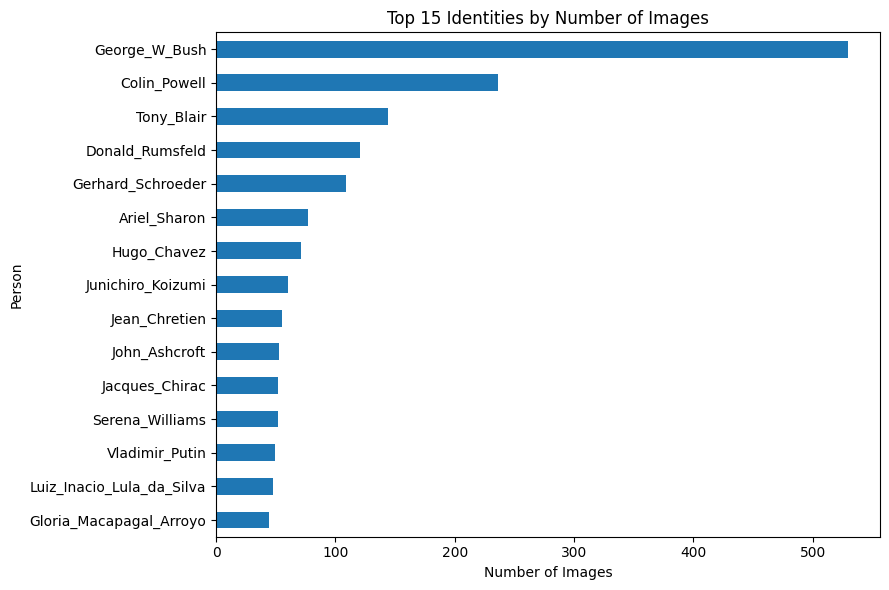

In [8]:

# CELL 6: Analyze images per person

identity_counts = df["person"].value_counts()

print("Number of identities:", len(identity_counts))
print("Average images per identity:", round(identity_counts.mean(), 2))
print("Maximum images for one identity:", identity_counts.max())

display(
    identity_counts.head(15)
    .rename("number_of_images")
    .to_frame()
)

identity_counts.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 15 Identities by Number of Images")
plt.xlabel("Number of Images")
plt.ylabel("Person")
plt.tight_layout()
plt.show()


Displaying some sample images.

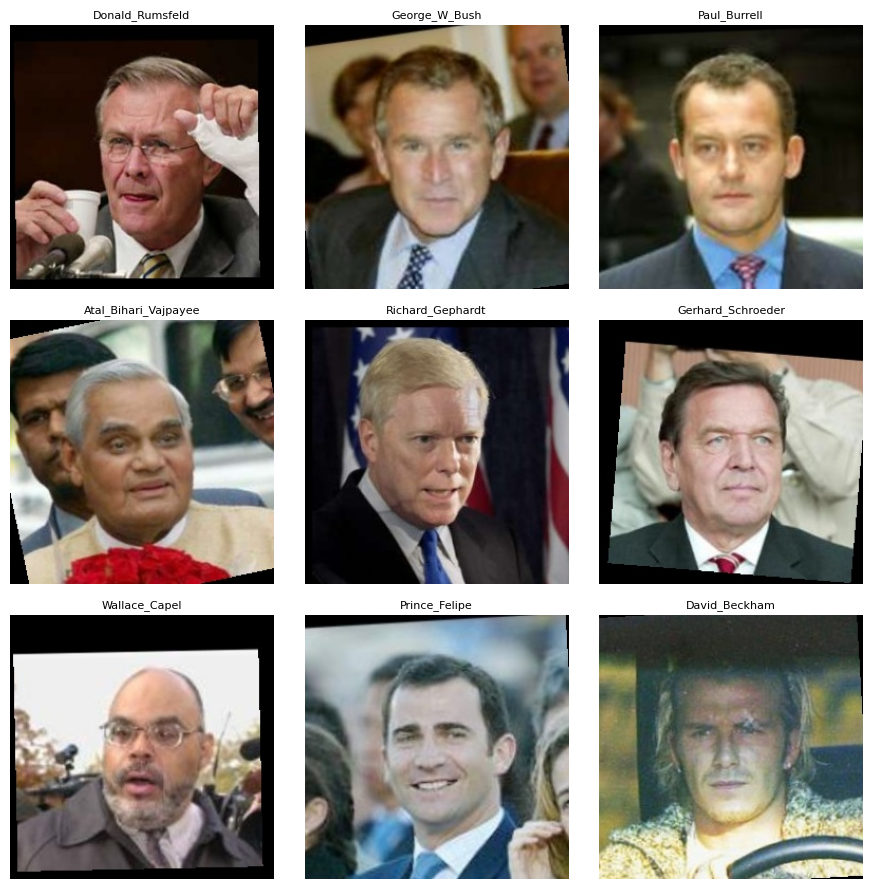

In [9]:

# CELL 7: Display sample face images

sample_df = df.sample(
    n=min(9, len(df)),
    random_state=42
)

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    try:
        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(row["person"], fontsize=8)
    except Exception:
        ax.set_title("Image could not be opened")

plt.tight_layout()
plt.show()


At this stage, your project has demonstrated data extraction, pandas, CSV storage and EDA.

Prepare the images for machine learning

In [10]:

# CELL 8: Select five identities

selected_people = [
    "George_W_Bush",
    "Colin_Powell",
    "Tony_Blair",
    "Donald_Rumsfeld",
    "Gerhard_Schroeder"
]

available_people = set(df["person"].unique())

selected_people = [
    person for person in selected_people
    if person in available_people
    and (df["person"] == person).sum() >= 10
]

print("Identities selected:", selected_people)

if len(selected_people) < 2:
    raise ValueError(
        "Not enough selected identities were found. "
        "Check the names in the metadata table."
    )

project_df = df[df["person"].isin(selected_people)].copy()

print("Selected images:", len(project_df))
display(project_df["person"].value_counts().to_frame("images"))


Identities selected: ['George_W_Bush', 'Colin_Powell', 'Tony_Blair', 'Donald_Rumsfeld', 'Gerhard_Schroeder']
Selected images: 1140


,images
person,
George_W_Bush,530
Colin_Powell,236
Tony_Blair,144
Donald_Rumsfeld,121
Gerhard_Schroeder,109


Convert images into numerical features

In [11]:

# CELL 9: Load and preprocess face images

IMAGE_SIZE = (50, 50)

X_list = []
y_list = []
valid_paths = []
failed_images = []

for _, row in project_df.iterrows():
    try:
        with Image.open(row["path"]) as img:
            img = img.convert("L")
            img = img.resize(IMAGE_SIZE)

            # Normalize pixels to the range 0 to 1
            pixels = np.asarray(img, dtype=np.float32) / 255.0

        X_list.append(pixels.flatten())
        y_list.append(row["person"])
        valid_paths.append(row["path"])

    except Exception as error:
        failed_images.append(row["path"])

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list)

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Images that could not be loaded:", len(failed_images))
print("Images successfully processed:", len(X))


Feature matrix shape: (1140, 2500)
Label array shape: (1140,)
Images that could not be loaded: 0
Images successfully processed: 1140


Split the data into training and testing sets

In [12]:

# CELL 10: Train/test split

X_train, X_test, y_train, y_test, paths_train, paths_test = (
    train_test_split(
        X,
        y,
        np.asarray(valid_paths),
        test_size=0.25,
        random_state=42,
        stratify=y
    )
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Training identities:", len(np.unique(y_train)))
print("Testing identities:", len(np.unique(y_test)))


Training images: 855
Testing images: 285
Training identities: 5
Testing identities: 5


Reduce features and train the SVM

In [13]:

# CELL 11: Build and train the machine-learning model

n_components = min(
    50,
    X_train.shape[0] - 1,
    X_train.shape[1]
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_components)),
    ("svm", SVC(kernel="rbf", C=10, gamma="scale"))
])

model.fit(X_train, y_train)

print("SVM model trained successfully!")
print("PCA components:", n_components)


SVM model trained successfully!
PCA components: 50


Evaluate the model

In [14]:

# CELL 12: Generate predictions and calculate accuracy

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test accuracy percentage: {accuracy * 100:.2f}%")

print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))


Test accuracy: 0.8105
Test accuracy percentage: 81.05%

Classification report:

                   precision    recall  f1-score   support

     Colin_Powell       0.85      0.76      0.80        59
  Donald_Rumsfeld       0.67      0.73      0.70        30
    George_W_Bush       0.84      0.94      0.89       133
Gerhard_Schroeder       0.81      0.78      0.79        27
       Tony_Blair       0.75      0.50      0.60        36

         accuracy                           0.81       285
        macro avg       0.78      0.74      0.76       285
     weighted avg       0.81      0.81      0.80       285



Creating confusion matrix

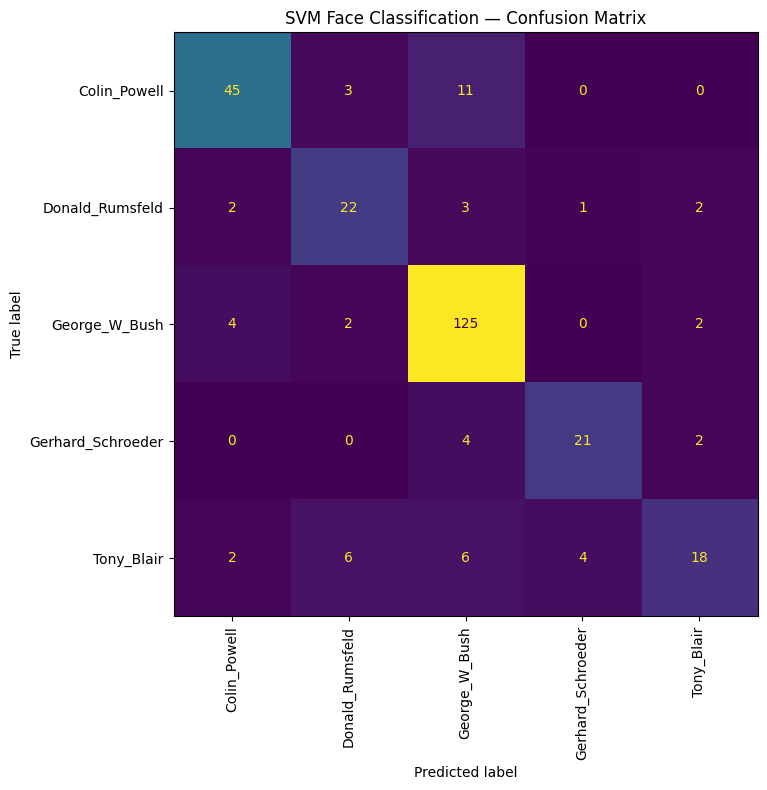

In [15]:

# CELL 13: Plot the confusion matrix

labels = sorted(np.unique(y))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(10, 8))
display_cm.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title("SVM Face Classification — Confusion Matrix")
plt.tight_layout()
plt.show()


Create the attendance CSV file

In [16]:

# CELL 14: Generate demonstration attendance records

session_date = datetime.now().strftime("%Y-%m-%d")
session_id = session_date + "_demo"

attendance = pd.DataFrame({
    "person": y_pred,
    "image_path": paths_test
})

attendance["date"] = session_date
attendance["session_id"] = session_id
attendance["timestamp"] = datetime.now().isoformat(timespec="seconds")

# One attendance entry per predicted identity per session
attendance = attendance.drop_duplicates(
    subset=["person", "session_id"]
).reset_index(drop=True)

ATTENDANCE_PATH = BASE_DIR / "attendance.csv"

attendance.to_csv(ATTENDANCE_PATH, index=False)

print("Attendance demonstration saved.")
display(attendance.head(10))
print("Unique identities recorded:", len(attendance))


Attendance demonstration saved.


,person,image_path,date,session_id,timestamp
0,Gerhard_Schroeder,/content/lfw_project/images/lfw_funneled/Gerha...,2026-10-22,2026-10-22_demo,2026-10-22T14:24:40
1,Colin_Powell,/content/lfw_project/images/lfw_funneled/Colin...,2026-10-22,2026-10-22_demo,2026-10-22T14:24:40
2,George_W_Bush,/content/lfw_project/images/lfw_funneled/Colin...,2026-10-22,2026-10-22_demo,2026-10-22T14:24:40
3,Tony_Blair,/content/lfw_project/images/lfw_funneled/Tony_...,2026-10-22,2026-10-22_demo,2026-10-22T14:24:40
4,Donald_Rumsfeld,/content/lfw_project/images/lfw_funneled/Donal...,2026-10-22,2026-10-22_demo,2026-10-22T14:24:40


Unique identities recorded: 5


Use SQLite as a database

In [17]:

# CELL 15: Create and populate the SQLite database

DB_PATH = BASE_DIR / "attendance.db"

with sqlite3.connect(DB_PATH) as conn:
    conn.execute("""
        CREATE TABLE IF NOT EXISTS attendance (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            person TEXT NOT NULL,
            session_id TEXT NOT NULL,
            date TEXT NOT NULL,
            timestamp TEXT NOT NULL,
            image_path TEXT,
            UNIQUE(person, session_id)
        )
    """)

    for _, row in attendance.iterrows():
        conn.execute("""
            INSERT OR IGNORE INTO attendance
            (person, session_id, date, timestamp, image_path)
            VALUES (?, ?, ?, ?, ?)
        """, (
            row["person"],
            row["session_id"],
            row["date"],
            row["timestamp"],
            row["image_path"]
        ))

    conn.commit()

print("SQLite database created and attendance saved.")


SQLite database created and attendance saved.


Demonstrate reading and modifying records.

In [18]:

# CELL 16: Read records from SQLite

with sqlite3.connect(DB_PATH) as conn:
    saved_records = pd.read_sql_query(
        "SELECT * FROM attendance ORDER BY person",
        conn
    )

display(saved_records)


,id,person,session_id,date,timestamp,image_path
0,2,Colin_Powell,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Colin...
1,5,Donald_Rumsfeld,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Donal...
2,3,George_W_Bush,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Colin...
3,1,Gerhard_Schroeder,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Gerha...
4,4,Tony_Blair,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Tony_...


In [19]:

# CELL 17: Demonstrate a database update

with sqlite3.connect(DB_PATH) as conn:
    conn.execute("""
        UPDATE attendance
        SET date = ?
        WHERE session_id = ?
    """, (session_date, session_id))

    conn.commit()

with sqlite3.connect(DB_PATH) as conn:
    updated_records = pd.read_sql_query(
        "SELECT * FROM attendance",
        conn
    )

print("Database update completed.")
display(updated_records.head())


Database update completed.


,id,person,session_id,date,timestamp,image_path
0,1,Gerhard_Schroeder,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Gerha...
1,2,Colin_Powell,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Colin...
2,3,George_W_Bush,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Colin...
3,4,Tony_Blair,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Tony_...
4,5,Donald_Rumsfeld,2026-10-22_demo,2026-10-22,2026-10-22T14:24:40,/content/lfw_project/images/lfw_funneled/Donal...


Limitation :This demonstration records model predictions, which can be wrong. Do not use it to mark real students present. A practical attendance system needs a validated confidence threshold, unknown-face rejection, duplicate protection, and human verification. The simple baseline also does not use a pretrained face-embedding model or a live camera.

Save the results and model

In [20]:

# CELL 18: Save evaluation results and the trained model

import joblib
import json

RESULTS_PATH = BASE_DIR / "evaluation_results.json"
MODEL_PATH = BASE_DIR / "svm_face_classifier.joblib"

results = {
    "project": "IDC409 Face Attendance",
    "classifier": "SVM with RBF kernel",
    "feature_reduction": "PCA",
    "number_of_classes": int(len(np.unique(y))),
    "training_images": int(len(X_train)),
    "testing_images": int(len(X_test)),
    "accuracy": float(accuracy),
    "pca_components": int(n_components)
}

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

joblib.dump(model, MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print("Results saved to:", RESULTS_PATH)

display(pd.DataFrame([results]))


Model saved to: /content/lfw_project/svm_face_classifier.joblib
Results saved to: /content/lfw_project/evaluation_results.json


,project,classifier,feature_reduction,number_of_classes,training_images,testing_images,accuracy,pca_components
0,IDC409 Face Attendance,SVM with RBF kernel,PCA,5,855,285,0.810526,50


Download your project files

In [21]:

# CELL 19: Create a ZIP containing the project outputs

import shutil

OUTPUT_ZIP = shutil.make_archive(
    "/content/IDC409_Face_Attendance",
    "zip",
    root_dir=BASE_DIR
)

print("Project files packaged successfully.")
print("ZIP path:", OUTPUT_ZIP)

from google.colab import files
files.download(OUTPUT_ZIP)


Project files packaged successfully.
ZIP path: /content/IDC409_Face_Attendance.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>